In [4]:
import tensorflow as tf
from tensorflow.keras import layers , models
import numpy as np
import matplotlib.pyplot as plt

In [5]:
# Set random seed for reproducibility
tf.random.set_seed(42)
np.random.seed(42)

In [6]:
# Generate synthetic binary classification dataset (small dataset to induce overfitting)
X_train = np.random.randn(500, 100)
y_train = np.random.randint(0, 2, size=(500, 1))

X_val = np.random.randn(200, 100)
y_val = np.random.randint(0, 2, size=(200, 1))

print(f"Training shape: {X_train.shape}, Validation shape: {X_val.shape}")

Training shape: (500, 100), Validation shape: (200, 100)


In [7]:
# Model 1: Baseline (Without Dropout)
def build_baseline_model():
    model = models.Sequential([
        layers.Input(shape=(100,)),
        layers.Dense(128, activation='relu'),
        layers.Dense(128, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ], name="Baseline_No_Dropout")
    return model

In [8]:
# Model 2: Regularized (With Dropout)
def build_dropout_model(dropout_rate=0.5):
    model = models.Sequential([
        layers.Input(shape=(100,)),
        
        layers.Dense(128, activation='relu'),
        layers.Dropout(dropout_rate),  # Randomly zeros 50% of activations during training
        
        layers.Dense(128, activation='relu'),
        layers.Dropout(dropout_rate),  # Randomly zeros 50% of activations during training
        
        layers.Dense(1, activation='sigmoid')
    ], name="Model_With_Dropout")
    return model

In [9]:
model_no_dropout = build_baseline_model()
model_dropout = build_dropout_model(dropout_rate=0.5)

model_dropout.summary()

E0000 00:00:1791881437.168460    2574 cuda_executor.cc:1690] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:68

W0000 00:00:1791881437.168819    3087 cuda_executor.cc:1710] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:77
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:107
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:112

W0000 00:00:1791881437.197102    2574 dlopen_checker.cc:38] Could not load dynamic library 'libcudart.so.12'; dlerror: libcudart.so.12: cannot open shared object file: No such file or directory
W0000 00:00:1791881437.197111    2

Model: "Model_With_Dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 128)            │        12,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,569 (115.50 KB)

 Trainable params: 29,569 (115.50 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
# Compile options
compile_kwargs = {
    'optimizer': 'adam',
    'loss': 'binary_crossentropy',
    'metrics': ['accuracy']
}

model_no_dropout.compile(**compile_kwargs)
model_dropout.compile(**compile_kwargs)

# Train Model WITHOUT Dropout
print("--- Training Baseline Model (No Dropout) ---")
history_no_dropout = model_no_dropout.fit(
    X_train, y_train,
    epochs=300,
    validation_data=(X_val, y_val),
    verbose=0
)

# Train Model WITH Dropout
print("--- Training Model WITH Dropout ---")
history_dropout = model_dropout.fit(
    X_train, y_train,
    epochs=300,
    validation_data=(X_val, y_val),
    verbose=0
)
print("Training Complete!")

--- Training Baseline Model (No Dropout) ---
--- Training Model WITH Dropout ---
Training Complete!


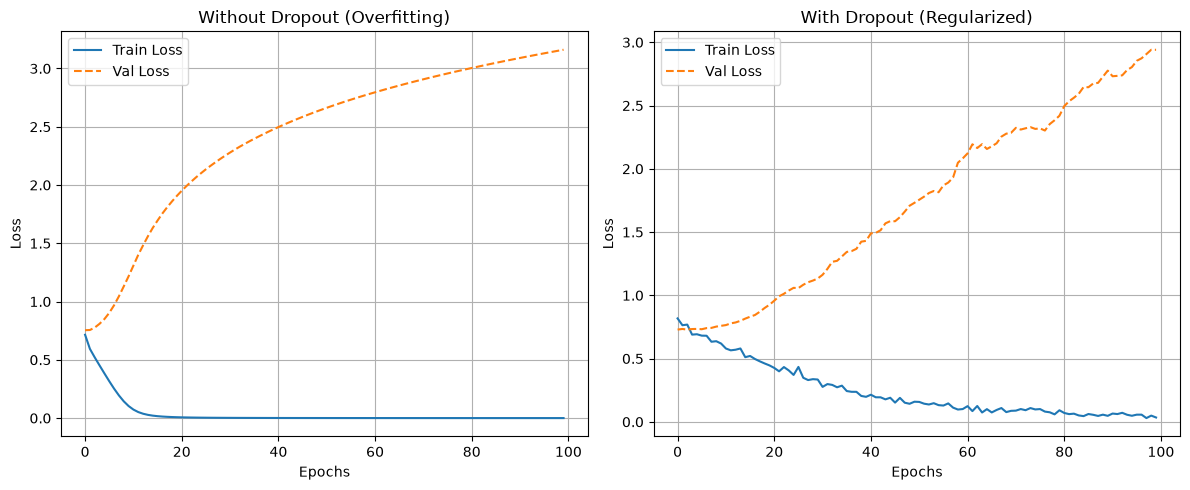

In [11]:
plt.figure(figsize=(12, 5))

# Plot Baseline Loss
plt.subplot(1, 2, 1)
plt.plot(history_no_dropout.history['loss'], label='Train Loss')
plt.plot(history_no_dropout.history['val_loss'], label='Val Loss', linestyle='--')
plt.title('Without Dropout (Overfitting)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot Dropout Loss
plt.subplot(1, 2, 2)
plt.plot(history_dropout.history['loss'], label='Train Loss')
plt.plot(history_dropout.history['val_loss'], label='Val Loss', linestyle='--')
plt.title('With Dropout (Regularized)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [14]:
import tensorflow as tf

# Check available physical devices
gpus = tf.config.list_physical_devices('GPU')
print("Num GPUs Available:", len(gpus))

if gpus:
    for gpu in gpus:
        print("Device Name:", gpu.name)
else:
    print("No GPU detected by TensorFlow.")

Num GPUs Available: 0
No GPU detected by TensorFlow.
